In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

df = pd.read_csv('../data/processed/spain_top50_staged.csv', parse_dates=['date'])
gaps = pd.read_csv('../data/processed/known_gap_dates.csv', parse_dates=['missing_date'])

print(f"Rows: {df.shape}")
print(f"Unique dates: {df['date'].nunique()}")
print(f"Known gap dates: {len(gaps)}")
print(df[['date', 'song', 'position', 'run_id', 'is_fringe', 'stage']].head())

Rows: (27750, 20)
Unique dates: 555
Known gap dates: 4
        date         song  position  run_id  is_fringe      stage
0 2025-06-02  0 CONFIANZA        40       1      False  New Entry
1 2025-06-05  0 CONFIANZA        31       2      False  New Entry
2 2025-06-06  0 CONFIANZA        25       2      False  New Entry
3 2025-06-07  0 CONFIANZA        23       2      False  New Entry
4 2025-06-08  0 CONFIANZA        23       2      False       Peak


In [2]:
all_dates = sorted(df['date'].unique())
first_date = all_dates[0]

# One row per run start = one entry; the first data date has no real entries
entries = df[(df['day_in_run'] == 1) & (df['date'] != first_date)]

daily = pd.DataFrame(index=pd.Index(all_dates[1:], name='date'))
daily['entries_all'] = entries.groupby('date').size()
daily['entries_nonfringe'] = entries[~entries['is_fringe']].groupby('date').size()
daily['new_songs'] = entries[entries['run_id'] == 1].groupby('date').size()
daily['re_entries'] = entries[entries['run_id'] > 1].groupby('date').size()
daily = daily.fillna(0).astype(int)

# Flag the first data date after each missing date
after_gap = [min(d for d in all_dates if d > g) for g in gaps['missing_date']]
daily['after_gap'] = daily.index.isin(after_gap)

print(daily.head())
print(f"\nDays measured: {len(daily)}  |  flagged after-gap days: {daily['after_gap'].sum()}")

print("\nTotals over all measured days:")
print(daily[['entries_all', 'entries_nonfringe', 'new_songs', 're_entries']].sum())

clean = daily[~daily['after_gap']]
print("\nPer-day stats (after-gap days excluded):")
print(clean[['entries_all', 'entries_nonfringe', 'new_songs', 're_entries']].describe().loc[['mean', '50%', 'min', 'max']])

            entries_all  entries_nonfringe  new_songs  re_entries  after_gap
date                                                                        
2024-05-19            0                  0          0           0      False
2024-05-20            0                  0          0           0      False
2024-05-21            4                  4          4           0      False
2024-05-22            1                  0          1           0      False
2024-05-23            0                  0          0           0      False

Days measured: 554  |  flagged after-gap days: 4

Totals over all measured days:
entries_all          953
entries_nonfringe    643
new_songs            525
re_entries           428
dtype: int64

Per-day stats (after-gap days excluded):
      entries_all  entries_nonfringe  new_songs  re_entries
mean         1.72               1.16   0.947273    0.772727
50%          1.00               1.00   0.000000    0.000000
min          0.00               0.00   0.000

In [3]:
busiest = daily.sort_values('entries_all', ascending=False).head(8)
busiest = busiest.assign(weekday=busiest.index.day_name())
print(busiest[['entries_all', 'new_songs', 're_entries', 'after_gap', 'weekday']])

top10_share = daily['entries_all'].nlargest(10).sum() / daily['entries_all'].sum()
print(f"\nShare of all entries on the 10 busiest days: {top10_share:.0%}")

print("\nEntries per day, percentiles:")
print(daily['entries_all'].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

            entries_all  new_songs  re_entries  after_gap   weekday
date                                                               
2025-04-28           23         22           1      False    Monday
2024-10-14           21         20           1      False    Monday
2025-11-24           20         20           0      False    Monday
2025-01-21           16         15           1      False   Tuesday
2025-11-17           15         14           1      False    Monday
2025-08-24           15         14           1      False    Sunday
2024-08-30           15         15           0      False    Friday
2024-12-28           13          1          12      False  Saturday

Share of all entries on the 10 busiest days: 17%

Entries per day, percentiles:
0.50     1.0
0.75     2.0
0.90     3.7
0.95     5.0
0.99    15.0
Name: entries_all, dtype: float64


In [4]:
def still_on_chart(day, lag):
    target = day + pd.Timedelta(days=lag)
    on_chart = df[df['date'] == target]
    if on_chart.empty:                      # target date is missing or past the data
        return np.nan
    entered = entries[entries['date'] == day]
    merged = entered.merge(on_chart[['song_key', 'artist_key']],
                           on=['song_key', 'artist_key'], how='left', indicator=True)
    return (merged['_merge'] == 'both').mean()

spikes = daily.sort_values('entries_all', ascending=False).head(8)[['entries_all']].copy()
spikes['still_there_1d'] = [still_on_chart(d, 1) for d in spikes.index]
spikes['still_there_3d'] = [still_on_chart(d, 3) for d in spikes.index]
print(spikes.round(2))

# Average entries by weekday (after-gap days excluded)
ok = daily[~daily['after_gap']]
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print()
print(ok.groupby(ok.index.day_name())['entries_all'].mean().reindex(weekdays).round(2))

            entries_all  still_there_1d  still_there_3d
date                                                   
2025-04-28           23            0.78            0.78
2024-10-14           21            1.00            1.00
2025-11-24           20            0.95            1.00
2025-01-21           16            0.38            0.38
2025-11-17           15            0.67            0.60
2025-08-24           15            0.40            0.27
2024-08-30           15            1.00            0.80
2024-12-28           13            1.00            0.92

date
Monday       3.36
Tuesday      2.47
Wednesday    1.28
Thursday     1.13
Friday       1.45
Saturday     1.22
Sunday       1.09
Name: entries_all, dtype: float64


In [5]:
ok = daily[~daily['after_gap']].copy()

# Weekday check using the median, which a few spike days can't distort
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print("Median entries by weekday:")
print(ok.groupby(ok.index.day_name())['entries_all'].median().reindex(weekdays))

# Monthly churn view
monthly = ok.groupby(ok.index.to_period('M')).agg(
    days=('entries_all', 'size'),
    mean_entries=('entries_all', 'mean'),
    median_entries=('entries_all', 'median'),
    mean_nonfringe=('entries_nonfringe', 'mean'),
    re_entries=('re_entries', 'sum'),
    total_entries=('entries_all', 'sum'),
)
monthly['churn_pct'] = (monthly['mean_entries'] / 50 * 100).round(1)
monthly['re_entry_share_pct'] = (monthly['re_entries'] / monthly['total_entries'] * 100).round(0)

print()
print(monthly[['days', 'mean_entries', 'median_entries', 'mean_nonfringe',
               'churn_pct', 're_entry_share_pct']].round(2))

Median entries by weekday:
date
Monday       2.0
Tuesday      2.0
Wednesday    1.0
Thursday     1.0
Friday       1.0
Saturday     1.0
Sunday       1.0
Name: entries_all, dtype: float64

         days  mean_entries  median_entries  mean_nonfringe  churn_pct  re_entry_share_pct
date                                                                                      
2024-05    13          1.54             1.0            0.54        3.1                30.0
2024-06    30          1.20             1.0            0.60        2.4                44.0
2024-07    31          1.00             1.0            0.68        2.0                35.0
2024-08    31          1.06             0.0            0.90        2.1                15.0
2024-09    30          1.33             0.5            1.10        2.7                38.0
2024-10    31          1.90             1.0            1.61        3.8                32.0
2024-11    30          1.50             1.0            0.97        3.0                

In [6]:
print(monthly.loc['2025-05':'2025-07',
      ['days', 'mean_entries', 'median_entries', 'mean_nonfringe', 'churn_pct', 're_entry_share_pct']].round(2))

daily.to_csv('../outputs/tables/daily_churn.csv')
monthly.to_csv('../outputs/tables/monthly_churn.csv')
print("\nSaved daily_churn.csv and monthly_churn.csv")

         days  mean_entries  median_entries  mean_nonfringe  churn_pct  re_entry_share_pct
date                                                                                      
2025-05    31          1.71             2.0            1.13        3.4                60.0
2025-06    30          1.90             1.0            1.17        3.8                49.0
2025-07    29          1.52             1.0            0.90        3.0                48.0

Saved daily_churn.csv and monthly_churn.csv


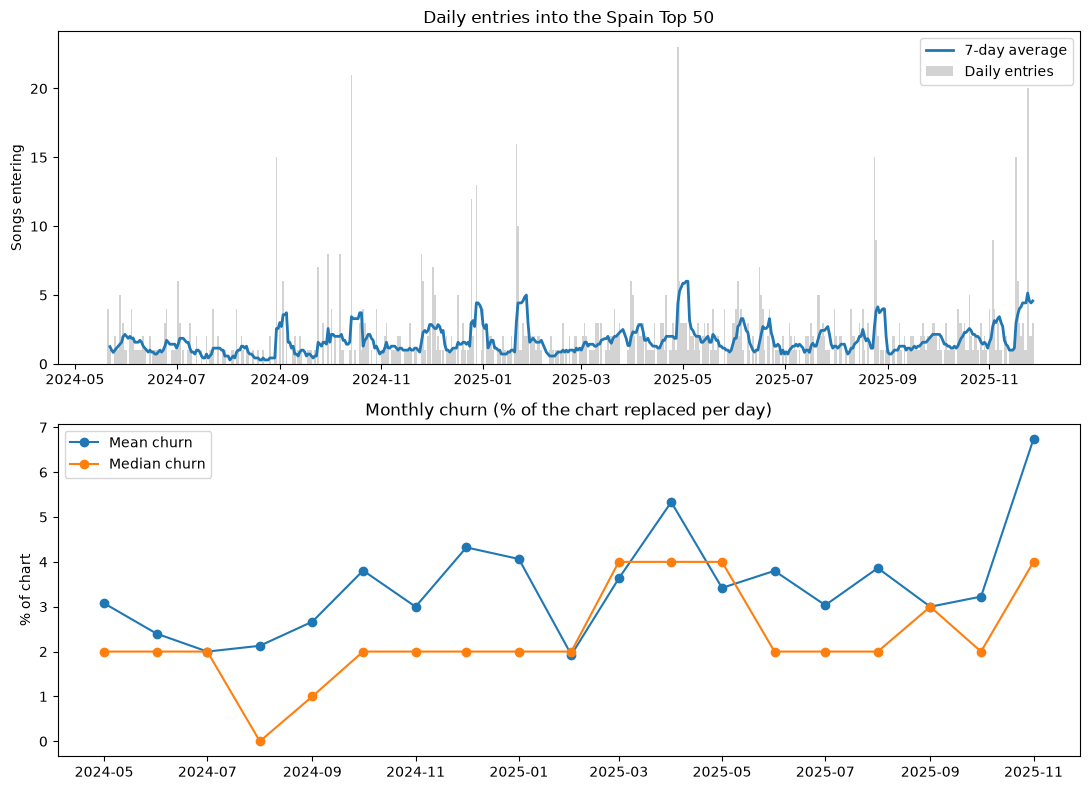

In [7]:
import matplotlib.pyplot as plt

plot_daily = daily['entries_all'].where(~daily['after_gap'])
rolling = plot_daily.rolling(7, min_periods=4).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].bar(plot_daily.index, plot_daily, color='lightgray', width=1.0, label='Daily entries')
axes[0].plot(rolling.index, rolling, color='tab:blue', linewidth=2, label='7-day average')
axes[0].set_title('Daily entries into the Spain Top 50')
axes[0].set_ylabel('Songs entering')
axes[0].legend()

months = monthly.index.to_timestamp()
axes[1].plot(months, monthly['mean_entries'] / 50 * 100, marker='o', label='Mean churn')
axes[1].plot(months, monthly['median_entries'] / 50 * 100, marker='o', label='Median churn')
axes[1].set_title('Monthly churn (% of the chart replaced per day)')
axes[1].set_ylabel('% of chart')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/churn_over_time.png', dpi=150)
plt.show()